# Teks — Regresi dari Teks (tebak angka: rating bintang, harga, skor esai)
**Kapan dipakai:** target berupa angka, bukan kelas.

**Langkah:** TF-IDF → model regresi linear → batasi hasil ke rentang target → RMSE/MAE.
Kalau target bertingkat (1–5) dan dinilai sebagai kelas, bulatkan prediksi lalu pakai QWK.

**Data demo:** ulasan Yelp (Inggris), target `stars` 1–5.

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge, SGDRegressor
from sklearn.metrics import cohen_kappa_score, mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline, make_union
from sklearn.svm import LinearSVR

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/text/regression"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/yelp_train.csv"
TEST_CSV = f"{DATA_FOLDER}/yelp_test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/yelp_test_labels.csv"   # hanya ada di data latihan

TEXT_COL = "text"
TARGET = "stars"
MIN_VALUE = 1      # prediksi dibatasi ke rentang target
MAX_VALUE = 5
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
print(train.isna().sum())
train.head()

train: (6000, 3) | test: (2000, 2)
id       0
text     0
stars    0
dtype: int64


,id,text,stars
0,723,Green catered my anniversary party recently. I...,4
1,7800,I love the food at Green. I've tried many othe...,5
2,2934,I was really teetering between 2-stars and 3-s...,3
3,781,Horrible. I have come here three times and ea...,1
4,1031,We stopped in opening day to check out what th...,1


## EDA: sebaran target dan panjang teks

stars
1    1210
2    1219
3    1196
4    1209
5    1166
Name: count, dtype: int64
korelasi panjang teks vs target: -0.154


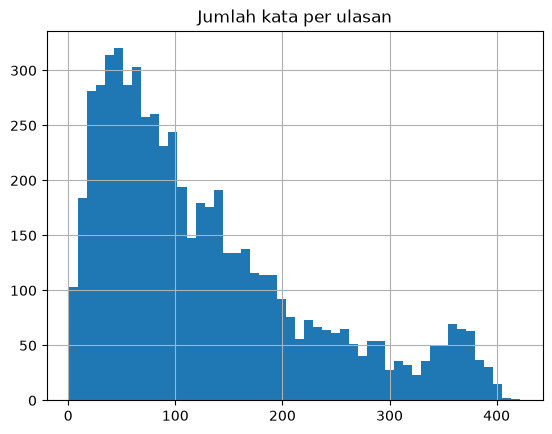

In [4]:
star_counts = train[TARGET].value_counts()
print(star_counts.sort_index())
word_counts = train[TEXT_COL].str.split().str.len()
print("korelasi panjang teks vs target:", round(word_counts.corr(train[TARGET]), 3))
word_counts.hist(bins=50)
plt.title("Jumlah kata per ulasan")
plt.show()

## Bersihkan teks
Tanda `'`, `!`, `?` dipertahankan karena membawa nada.

In [5]:
def clean_text(text):
    text = text.lower()
    text = text.replace("\\n", " ")
    text = re.sub(r"http\S+", " ", text)
    text = re.sub(r"[^a-z0-9'!?\s]", " ", text)
    return text


print(clean_text("GREAT food!!\\nSee http://yelp.com :)"))

train[TEXT_COL] = train[TEXT_COL].fillna("").apply(clean_text)
test[TEXT_COL] = test[TEXT_COL].fillna("").apply(clean_text)

great food!! see     


## Split train / validasi

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    train[TEXT_COL], train[TARGET], test_size=0.2, random_state=SEED
)

## Model
Pilih SATU vectorizer dan SATU model: hapus `#` di baris yang ingin dipakai.

In [7]:
vectorizer = make_union(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                        TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3,
                                        sublinear_tf=True))
# vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

model = Ridge(alpha=3.0)                          # cepat, kuat untuk TF-IDF
# model = LinearSVR(C=0.1, max_iter=5000)
# model = SGDRegressor(alpha=1e-5, random_state=SEED)
# model = LGBMRegressor(n_estimators=400, learning_rate=0.05, random_state=SEED, verbose=-1)

pipe = make_pipeline(vectorizer, model)
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('featureunion', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('tfidfvectorizer-1', ...), ('tfidfvectorizer-2', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0

## Evaluasi: RMSE/MAE (angka) dan QWK (setelah dibulatkan ke kelas)

RMSE: 0.9145
MAE : 0.7318
QWK (dibulatkan): 0.6912
akurasi tepat bintang: 0.415


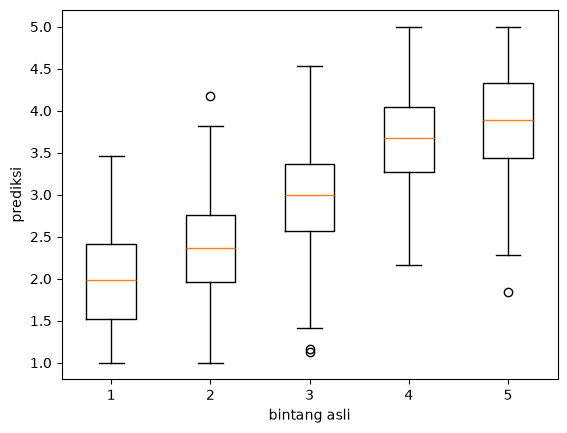

In [8]:
val_values = np.clip(pipe.predict(X_val), MIN_VALUE, MAX_VALUE)
val_rounded = np.round(val_values).astype(int)
print("RMSE:", round(root_mean_squared_error(y_val, val_values), 4))
print("MAE :", round(mean_absolute_error(y_val, val_values), 4))
print("QWK (dibulatkan):", round(cohen_kappa_score(y_val, val_rounded, weights="quadratic"), 4))
print("akurasi tepat bintang:", round((val_rounded == y_val).mean(), 4))

true_stars = y_val.to_numpy()
groups = []
for star in range(MIN_VALUE, MAX_VALUE + 1):
    groups.append(val_values[true_stars == star])
plt.boxplot(groups)
plt.xlabel("bintang asli")
plt.ylabel("prediksi")
plt.show()

## Latih ulang di semua data + submission
Butuh bilangan bulat? Tambah baris `predictions = np.round(predictions).astype(int)`.

In [9]:
pipe.fit(train[TEXT_COL], train[TARGET])
predictions = np.clip(pipe.predict(test[TEXT_COL]), MIN_VALUE, MAX_VALUE)

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["stars"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,stars
0,2034,1.881404
1,5025,2.222289
2,3943,1.703581
3,4076,2.579968
4,1504,3.103957


## Cek dengan kunci jawaban latihan
**HAPUS sel ini saat lomba**: file kunci hanya ada di data latihan.

In [10]:
test_key = pd.read_csv(TEST_KEY_CSV)["stars"]
print("RMSE test (kunci latihan):", round(root_mean_squared_error(test_key, predictions), 4))

RMSE test (kunci latihan): 0.8747
